# Spacecraft anomaly detection

#### Imports

In [9]:
import numpy as np
import matplotlib.pyplot as plt

#### Dataset : 


Train values for channel T-1 : shape = (2875, 25)
Test values for channel T-1 : shape = (8612, 25)


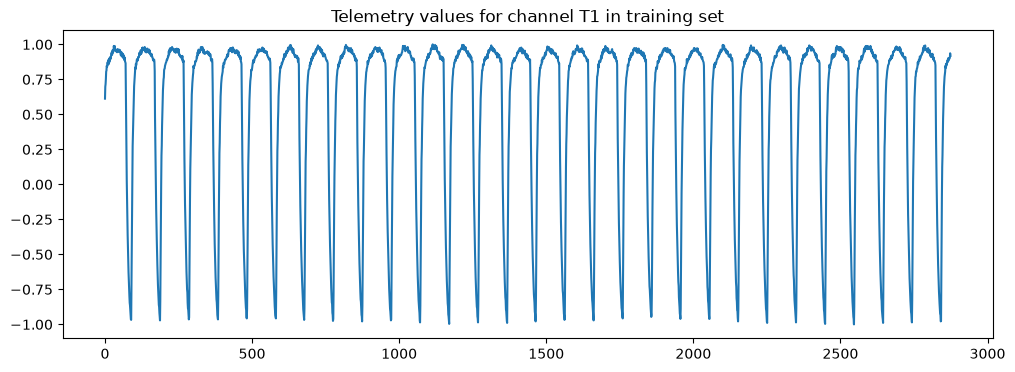

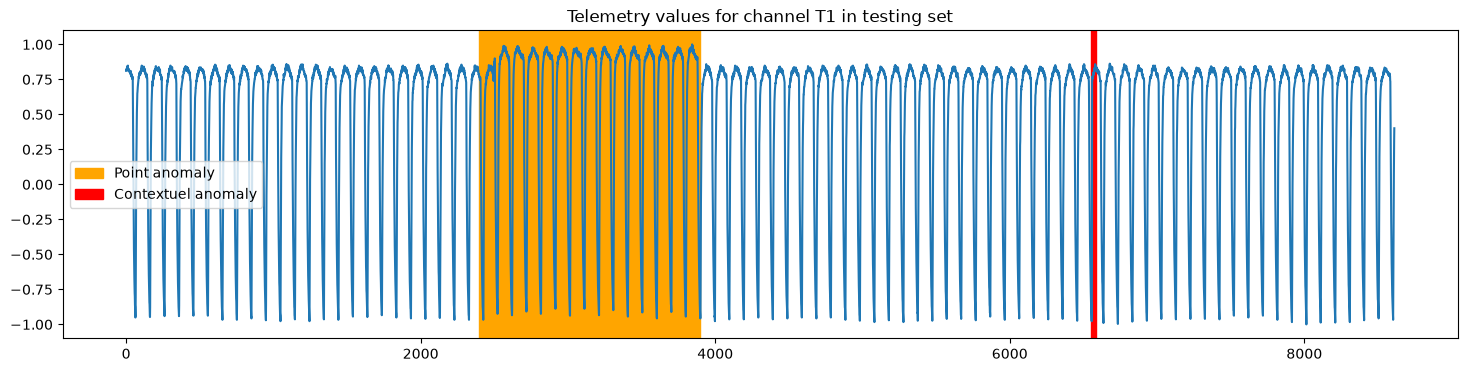

In [25]:
train_T1 = np.load("../data/train/T-1.npy")
test_T1 = np.load("../data/test/T-1.npy")
print("Train values for channel T-1 : shape =", train_T1.shape)
print("Test values for channel T-1 : shape =", test_T1.shape)

t_train = np.arange(0, len(train_T1))
t_test = np.arange(0, len(test_T1))

# Plot telemetry for training set
plt.figure(figsize=(12, 4))
plt.plot(t_train, train_T1[:,0])
plt.title("Telemetry values for channel T1 in training set")
plt.show()

# Plot telemetry for testing set, and detected anomalies (labeled as point and contextual)
point_anomaly = [2399, 3898]
contextual_anomaly = [6550, 6585]
fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(t_test, test_T1[:,0])
ax.axvspan(point_anomaly[0], point_anomaly[1], color="orange", label="Point anomaly" )
ax.axvspan(contextual_anomaly[0], contextual_anomaly[1], color="red", label="Contextuel anomaly")
ax.legend()
ax.set_title("Telemetry values for channel T1 in testing set")
plt.show()


#### Fitting LSTMs :
For each channel (ie file) of the training set, train a LSTM to predict normal telemetry values using as input previous telemtry values and input commands. 
As given in the paper, LSTM parameters : 
- window : 250 (take 250 previous measures as input)
- n_inputs: 25 (SMAP), 55 (MSL) -> each file is of shape (n_timesteps, n_inputs); n_inputs varies between SMAP and MSL
- hidden layers : 2
- units in hidden layers : 80
- dropout : 0.3
- batch size : 64, optimizer : Adam, training iterations : 35